# Challenge 1: datos y análisis exploratorio

Tu primera responsabilidad es preparar una fuente de datos confiable para el proyecto de clasificación de vinos.

**Entrada:** `data/raw/wine.csv`  
**Salidas:** `data/processed/train.csv`, `data/processed/test.csv` y `artifacts/data_contract.json`

> El conjunto de test se crea aquí, pero no debe explorarse ni utilizarse después del split.

## Objetivos

- cargar y validar datos externos;
- identificar problemas básicos de calidad;
- crear un split reproducible y estratificado;
- realizar EDA únicamente sobre entrenamiento;
- guardar datos y metadatos para la siguiente etapa.

In [1]:
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split

np.random.seed(42)
plt.rcParams["figure.figsize"] = (7, 4)

In [2]:
from pathlib import Path

PROJECT_DIR = Path.cwd()
RAW_DATA_DIR = PROJECT_DIR / "data" / "raw"
PROCESSED_DATA_DIR = PROJECT_DIR / "data" / "processed"
ARTIFACTS_DIR = PROJECT_DIR / "artifacts"
REPORTS_DIR = PROJECT_DIR / "reports"

for directory in (PROCESSED_DATA_DIR, ARTIFACTS_DIR, REPORTS_DIR):
    directory.mkdir(parents=True, exist_ok=True)

RANDOM_STATE = 42

## 1. Carga y profiling

In [3]:
DATA_PATH = RAW_DATA_DIR / "wine.csv"

df = pd.read_csv(DATA_PATH)
print("Archivo cargado:", DATA_PATH.name)
df.head()


Archivo cargado: wine.csv


,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline,target
0,14.23,1.71,2.43,15.6,127.0,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065.0,0
1,13.20,1.78,2.14,11.2,100.0,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050.0,0
2,13.16,2.36,2.67,18.6,101.0,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185.0,0
3,14.37,1.95,2.50,16.8,113.0,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480.0,0
4,13.24,2.59,2.87,21.0,118.0,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735.0,0


In [4]:
print("Forma:", df.shape)
print("\nTipos de datos:")
print(df.dtypes.value_counts())

print("\nValores nulos por columna (total):", int(df.isna().sum().sum()))
print("Filas duplicadas:", int(df.duplicated().sum()))

print("\nDistribución de target:")
dist = pd.DataFrame({
    "conteo": df["target"].value_counts().sort_index(),
    "proporción": df["target"].value_counts(normalize=True).sort_index().round(3),
})
print(dist)

print("\nResumen estadístico (rangos de escala):")
df.describe().T[["mean", "std", "min", "max"]].round(2)


Forma: (178, 14)

Tipos de datos:
float64    13
int64       1
Name: count, dtype: int64

Valores nulos por columna (total): 0
Filas duplicadas: 0

Distribución de target:
        conteo  proporción
target                    
0           59       0.331
1           71       0.399
2           48       0.270

Resumen estadístico (rangos de escala):


,mean,std,min,max
alcohol,13.00,0.81,11.03,14.83
malic_acid,2.34,1.12,0.74,5.80
ash,2.37,0.27,1.36,3.23
alcalinity_of_ash,19.49,3.34,10.60,30.00
magnesium,99.74,14.28,70.00,162.00
total_phenols,2.30,0.63,0.98,3.88
flavanoids,2.03,1.00,0.34,5.08
nonflavanoid_phenols,0.36,0.12,0.13,0.66
proanthocyanins,1.59,0.57,0.41,3.58
color_intensity,5.06,2.32,1.28,13.00


**Conclusión de calidad:**

> El dataset tiene **178 filas y 14 columnas**: 13 variables químicas numéricas (`float64`) y la columna `target` (`int64`) con 3 clases de vino (0, 1, 2). **No hay valores nulos ni filas duplicadas** y todos los tipos son correctos, así que no hace falta eliminar ni corregir registros.
>
> Hay dos puntos a considerar en el modelado:
> - Las clases están **moderadamente desbalanceadas** (71 / 59 / 48, es decir 40 % / 33 % / 27 %). Por eso el split debe ser **estratificado** y conviene reportar también F1 macro.
> - Las variables tienen **escalas muy distintas**: `proline` llega a valores mayores de 1 000, mientras `hue` o `nonflavanoid_phenols` son menores que 2. Los modelos basados en distancias o gradiente (KNN, regresión logística) necesitarán estandarización, que se hará dentro del pipeline en el Challenge 2 para evitar fuga de datos.
>
> Aunque hoy no hay nulos, se dejará un `SimpleImputer` en los pipelines como salvaguarda para datos nuevos en producción.


## 2. Split train/test

In [5]:
TEST_SIZE = 0.20

train_df, test_df = train_test_split(
    df,
    test_size=TEST_SIZE,
    stratify=df["target"],
    random_state=RANDOM_STATE,
)

print("Proporción de clases en train:", train_df["target"].value_counts(normalize=True).sort_index().round(3).to_dict())
print("Proporción de clases en test :", test_df["target"].value_counts(normalize=True).sort_index().round(3).to_dict())


Proporción de clases en train: {0: 0.331, 1: 0.401, 2: 0.268}
Proporción de clases en test : {0: 0.333, 1: 0.389, 2: 0.278}


In [6]:
# Verificación del split
assert len(train_df) + len(test_df) == len(df)
assert set(train_df.index).isdisjoint(set(test_df.index))
print("Train:", train_df.shape)
print("Test:", test_df.shape)

Train: (142, 14)
Test: (36, 14)


## 3. EDA sobre entrenamiento

Incluye:

- distribución de clases;
- distribuciones o boxplots de variables relevantes;
- correlaciones;
- tres hallazgos que puedan influir en el modelado.

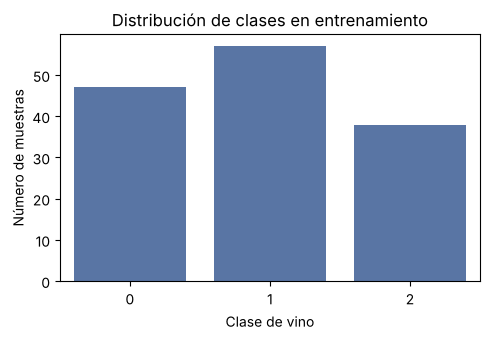

Variables ordenadas por poder discriminante (F de ANOVA, train):
flavanoids                      224.8
proline                         161.5
od280/od315_of_diluted_wines    144.8
color_intensity                 103.9
alcohol                          98.5
hue                              79.5
total_phenols                    72.3
malic_acid                       29.1
alcalinity_of_ash                27.5
proanthocyanins                  23.3
nonflavanoid_phenols             20.8
ash                              12.9
magnesium                         9.2
dtype: float64


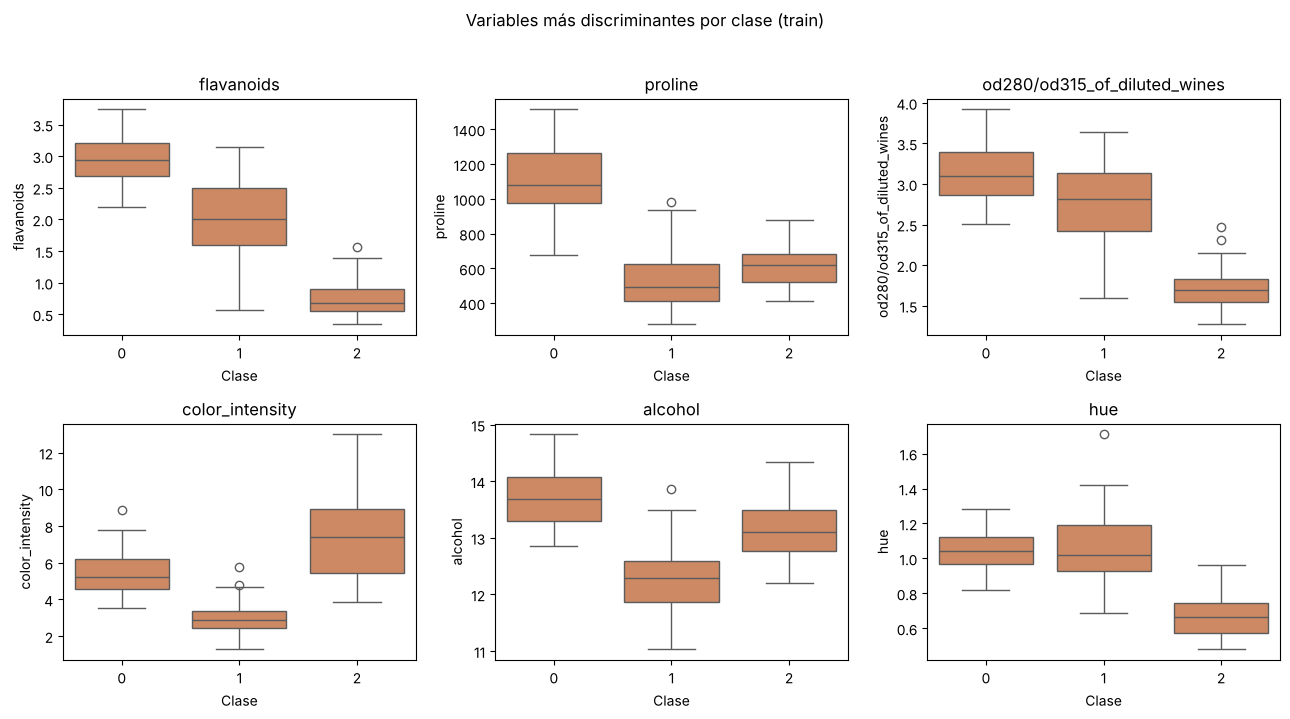

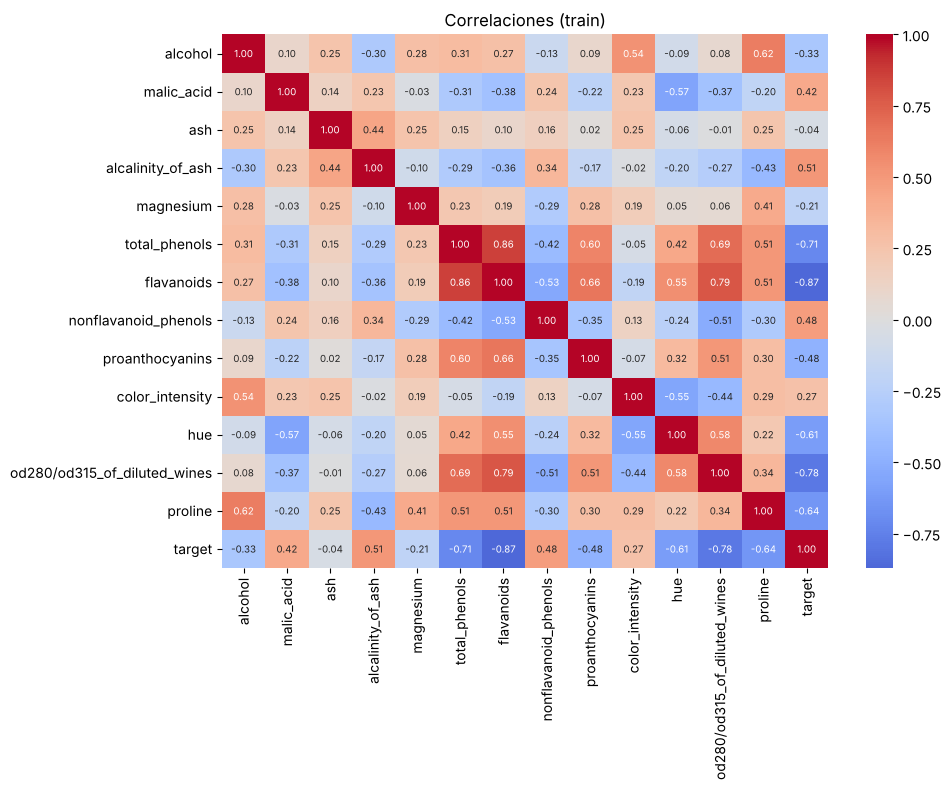


Pares de variables más correlacionados:
total_phenols  flavanoids                      0.861
flavanoids     od280/od315_of_diluted_wines    0.786
total_phenols  od280/od315_of_diluted_wines    0.695
flavanoids     proanthocyanins                 0.657
alcohol        proline                         0.621
dtype: float64


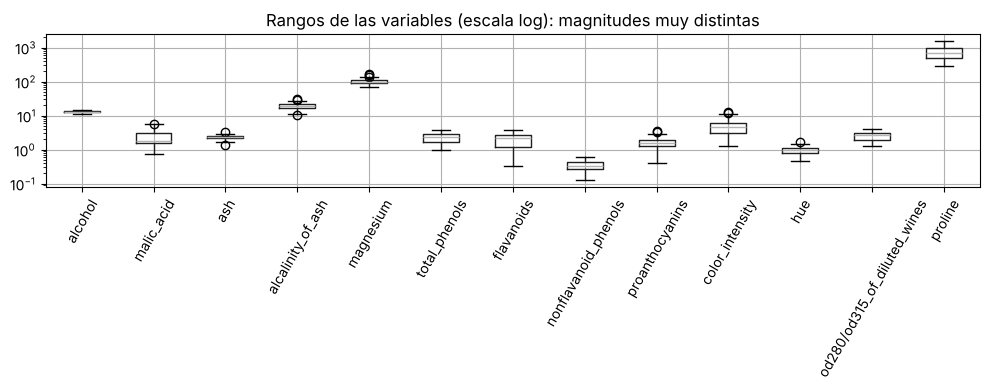

In [7]:
features = [c for c in train_df.columns if c != "target"]

# 1) Distribución de clases (solo train)
fig, ax = plt.subplots(figsize=(5, 3.5))
sns.countplot(data=train_df, x="target", ax=ax, color="#4C72B0")
ax.set_title("Distribución de clases en entrenamiento")
ax.set_xlabel("Clase de vino")
ax.set_ylabel("Número de muestras")
plt.tight_layout()
plt.show()

# 2) Boxplots por clase de las variables más discriminantes
#    (ranking por estadístico F de ANOVA calculado SOLO en train)
from sklearn.feature_selection import f_classif
f_stat, _ = f_classif(train_df[features], train_df["target"])
ranking = pd.Series(f_stat, index=features).sort_values(ascending=False)
print("Variables ordenadas por poder discriminante (F de ANOVA, train):")
print(ranking.round(1))

top = ranking.index[:6]
fig, axes = plt.subplots(2, 3, figsize=(13, 7))
for ax, col in zip(axes.ravel(), top):
    sns.boxplot(data=train_df, x="target", y=col, ax=ax, color="#DD8452")
    ax.set_title(col)
    ax.set_xlabel("Clase")
fig.suptitle("Variables más discriminantes por clase (train)", y=1.02)
plt.tight_layout()
plt.show()

# 3) Matriz de correlaciones
fig, ax = plt.subplots(figsize=(10, 8))
corr = train_df.corr()
sns.heatmap(corr, cmap="coolwarm", center=0, annot=True, fmt=".2f",
            annot_kws={"size": 7}, ax=ax)
ax.set_title("Correlaciones (train)")
plt.tight_layout()
plt.show()

# Pares de variables con correlación alta
pairs = (corr.drop(index="target", columns="target")
             .where(np.triu(np.ones((len(features), len(features))), k=1).astype(bool))
             .stack()
             .sort_values(key=abs, ascending=False))
print("\nPares de variables más correlacionados:")
print(pairs.head(5).round(3))

# 4) Escalas de las variables
fig, ax = plt.subplots(figsize=(10, 4))
train_df[features].boxplot(ax=ax, rot=60)
ax.set_yscale("log")
ax.set_title("Rangos de las variables (escala log): magnitudes muy distintas")
plt.tight_layout()
plt.show()


**Hallazgos:**

1. **Hay variables muy discriminantes, así que se esperan modelos con alta exactitud.** `flavanoids` (F ≈ 225), `proline` (F ≈ 162), `od280/od315` (F ≈ 145) y `color_intensity` (F ≈ 104) separan bien las clases. La clase 2 tiene `flavanoids` muy bajos (mediana 0.68 frente a 2.94 y 2.01) y `hue` bajo (0.66). La clase 0 se distingue por `proline` alto (≈ 1 080 frente a ≈ 500–620). La clase 1 tiene la menor `color_intensity` (2.9 frente a 5.3 y 7.4). Con pocas variables bien elegidas ya se distinguen las tres clases. Un árbol de decisión puede aprovechar estos umbrales y los modelos lineales también deberían funcionar bien.
2. **Existe multicolinealidad entre las variables fenólicas.** `total_phenols`–`flavanoids` tienen r = 0.86, `flavanoids`–`od280/od315` r = 0.79 y `total_phenols`–`od280/od315` r = 0.70. Aportan información redundante. Esto no afecta mucho a la exactitud, pero vuelve inestables los coeficientes de una regresión logística sin regularización. Conviene usar regularización (parámetro `C`) y no interpretar cada coeficiente por separado.
3. **Las escalas son muy heterogéneas y las clases están algo desbalanceadas.** `proline` y `magnesium` están en cientos o miles y otras variables son menores que 1. Para KNN y regresión logística es obligatorio estandarizar, dentro del pipeline para no filtrar información de validación. Los árboles no lo necesitan. El desbalance moderado (40 / 33 / 27 %) exige validación cruzada **estratificada** y reportar F1 macro además de accuracy.


## 4. Persistencia de datos y contrato

In [8]:
train_out = train_df.reset_index(drop=True)
test_out = test_df.reset_index(drop=True)

train_out.to_csv(PROCESSED_DATA_DIR / "train.csv", index=False)
test_out.to_csv(PROCESSED_DATA_DIR / "test.csv", index=False)

data_contract = {
    "target": "target",
    "features": features,
    "random_state": RANDOM_STATE,
    "test_size": TEST_SIZE,
    "n_train": int(len(train_out)),
    "n_test": int(len(test_out)),
    "classes": sorted(int(c) for c in df["target"].unique()),
}

(ARTIFACTS_DIR / "data_contract.json").write_text(
    json.dumps(data_contract, indent=2, ensure_ascii=False), encoding="utf-8"
)
print(json.dumps(data_contract, indent=2, ensure_ascii=False))


{
  "target": "target",
  "features": [
    "alcohol",
    "malic_acid",
    "ash",
    "alcalinity_of_ash",
    "magnesium",
    "total_phenols",
    "flavanoids",
    "nonflavanoid_phenols",
    "proanthocyanins",
    "color_intensity",
    "hue",
    "od280/od315_of_diluted_wines",
    "proline"
  ],
  "random_state": 42,
  "test_size": 0.2,
  "n_train": 142,
  "n_test": 36,
  "classes": [
    0,
    1,
    2
  ]
}


In [9]:
# Verificación de entrega
assert (PROCESSED_DATA_DIR / "train.csv").exists()
assert (PROCESSED_DATA_DIR / "test.csv").exists()
assert (ARTIFACTS_DIR / "data_contract.json").exists()
print("Challenge 1 completado.")

Challenge 1 completado.


## Checklist

- [x] Cargué el CSV desde `data/raw`.
- [x] Revisé calidad y distribución de la clase.
- [x] Realicé un split estratificado.
- [x] No exploré el conjunto de test.
- [x] Guardé los tres artefactos requeridos.
